# 14 自己训练一个微型字符 GPT

## 1 让小模型接着写一句话

给出 `the `，让模型继续写。刚开始它只有随机权重，字母往往拼不成词；训练之后，我们希望它能接出语料中出现过的词和句子结构。这一课就用上一课搭好的网络完成这件事。

语料由主语、动词与时间描述组合成27句，例如 `the sun glows slowly.`。这些句子短，规律也看得见，便于判断模型究竟学到了字符搭配、完整词，还是常常重复的片段。

18句用于学习权重，5句用于比较后续配置，另外4句留作测试。按完整句子拆开，便能观察模型面对未用于训练的句子组合时的表现。下一格生成并打印其中的一段。

In [1]:
from support import ROOT, check, show, style

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
torch.set_num_threads(1)
torch.manual_seed(7)
style()

In [3]:
sentences = [f'{subject} {verb} {ending}.\n'
             for subject in ['the sun','a star','the moon']
             for verb in ['moves','glows','rises']
             for ending in ['slowly','quietly','today']]
order = np.random.default_rng(7).permutation(len(sentences))
train_text = ''.join(sentences[i] for i in order[:18])
val_text = ''.join(sentences[i] for i in order[18:23])
test_text = ''.join(sentences[i] for i in order[23:])
print('训练句子示例：',repr(train_text[:90]))

训练句子示例： 'a star rises today.\nthe sun glows quietly.\nthe moon rises quietly.\na star glows quietly.\nt'


字符词表事先固定为换行、空格、小写字母与句点。字典把字符映射为整数；解码按相反方向查表。一个字符就是这一课的一个 token。

In [4]:
alphabet = '\n abcdefghijklmnopqrstuvwxyz.'
stoi = {character:i for i,character in enumerate(alphabet)}
def encode(text):
    return torch.tensor([stoi[c] for c in text],dtype=torch.long)
def decode(ids):
    return ''.join(alphabet[int(i)] for i in ids)
train_ids,val_ids,test_ids = map(encode,[train_text,val_text,test_text])
print(encode('the sun.'),decode(encode('the sun.')))

tensor([21,  9,  6,  1, 20, 22, 15, 28]) the sun.


### 练习 g01：实现一段编码

用 stoi 将字符串 moon 变成整数张量。

In [5]:
ex_g01_ids = None

In [6]:
# 填写上一格后，运行检查。
check('moon的编码',ex_g01_ids,encode('moon'))

待填写：moon的编码


<details>
<summary>提示</summary>

逐字符查字典；Embedding 的索引类型应为 long。

</details>

<details>
<summary>参考答案</summary>

```python
ex_g01_ids = torch.tensor([stoi[c] for c in 'moon'],dtype=torch.long)
```

</details>

## 2 一份窗口同时提供输入和标签

一段原文自己就提供了练习题和答案。例如读到 `the`，下一字符是空格；读到 `the s`，下一字符是 `u`。把原文复制一份、错开一个位置，就能一次取得许多这样的预测任务。

窗口起点为 s、长度为 T：输入取 `[s:s+T]`，目标取 `[s+1:s+T+1]`。下面打印的两行正好差一位。目标数组虽然整行存着，因果 mask 仍让位置 t 只读取它自己的前缀。

In [7]:
context = 16
x0,y0 = train_ids[:context],train_ids[1:context+1]
print('输入：',repr(decode(x0)))
print('标签：',repr(decode(y0)))
print('逐个检查：',[(decode([a]),decode([b])) for a,b in zip(x0[:5],y0[:5])])

输入： 'a star rises tod'
标签： ' star rises toda'
逐个检查： [('a', ' '), (' ', 's'), ('s', 't'), ('t', 'a'), ('a', 'r')]


In [8]:
def get_batch(data,batch_size=16):
    starts = torch.randint(len(data)-context,(batch_size,))
    x = torch.stack([data[s:s+context] for s in starts])
    y = torch.stack([data[s+1:s+context+1] for s in starts])
    return x,y
xb,yb = get_batch(train_ids)
print('输入和标签：',xb.shape,yb.shape)

输入和标签： torch.Size([16, 16]) torch.Size([16, 16])


### 练习 g02：写出错开一位的目标

数组为 `[0,1,2,3,4,5]`，起点 1、窗口长度 3。

In [9]:
ex_g02_x = None
ex_g02_y = None

In [10]:
# 填写上一格后，运行检查。
check('窗口输入',ex_g02_x,[1,2,3])
check('下一位标签',ex_g02_y,[2,3,4])

待填写：窗口输入
待填写：下一位标签


<details>
<summary>提示</summary>

输入是位置1、2、3；目标是2、3、4。

</details>

<details>
<summary>参考答案</summary>

```python
ex_g02_data=torch.arange(6)
ex_g02_x=ex_g02_data[1:4]
ex_g02_y=ex_g02_data[2:5]
```

</details>

## 3 每个位置都是一次词表分类

TinyGPT 为每个位置给出一张“下个字符分数表”。第13课写过的定义保存在 `models/tiny_gpt.py`，这里将它用于真正的训练。输出 `(B,T,V)` 的最后一个轴列出所有字符的分数。

每个位置都有一个真实的后续字符，所以可以把 B、T 合成一轴，得到许多个词表分类任务。交叉熵接收 `(B×T,V)` 分数和 `(B×T,)` 整数目标：

$$L=-\frac1{BT}\sum_{b,t}\log p_\theta(y_{b,t}\mid x_{b,\le t}).$$

如果真实字符的概率很小，负对数损失就大；提高它的概率，损失便下降。这个信号会穿过输出层、Transformer 块，一直回到字符与位置嵌入。

In [11]:
from models.tiny_gpt import TinyGPT
torch.manual_seed(7)
config = dict(vocab_size=len(alphabet),context=context,width=24,heads=2,depth=1)
model = TinyGPT(**config)
logits = model(xb)
loss = F.cross_entropy(logits.reshape(-1,len(alphabet)),yb.reshape(-1))
print('logits:',logits.shape,'loss:',loss.item())

logits: torch.Size([16, 16, 29]) loss: 3.586716413497925


### 练习 g03：正确展开位置

把 logits 和 yb 排成交叉熵需要的两个形状。

In [12]:
ex_g03_scores = None
ex_g03_targets = None

In [13]:
# 填写上一格后，运行检查。
check('分数形状',None if ex_g03_scores is None else ex_g03_scores.shape,(256,len(alphabet)))
check('标签形状',None if ex_g03_targets is None else ex_g03_targets.shape,(256,))

待填写：分数形状
待填写：标签形状


<details>
<summary>提示</summary>

只合并 B、T 两轴，保留完整词表轴。

</details>

<details>
<summary>参考答案</summary>

```python
ex_g03_scores=logits.reshape(-1,len(alphabet))
ex_g03_targets=yb.reshape(-1)
```

</details>

每次从训练文本取一批窗口，网络为所有位置给分，损失再把修正方向传回参数。这个循环与第06课相同；变化的是输入、目标和模型。AdamW 的学习率控制更新尺度，weight_decay 在更新中对权重施加衰减。

In [14]:
optimizer = torch.optim.AdamW(model.parameters(),lr=.004,weight_decay=.01)
history = []
for step in range(140):
    model.train()
    xb,yb = get_batch(train_ids)
    scores = model(xb)
    loss = F.cross_entropy(scores.reshape(-1,len(alphabet)),yb.reshape(-1))
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    history.append(loss.item())
print('前10步平均loss：',np.mean(history[:10]),'后10步：',np.mean(history[-10:]))

前10步平均loss： 3.2186142444610595 后10步： 0.3790708750486374


前10步与后10步的平均损失，给出了这140次更新的两个截面。下面的整条曲线还能看见中间的波动：不同窗口的难度不同，一次较高的损失不等于训练倒退。随后用完整的验证与测试文本，查看未用于更新权重的字符预测。

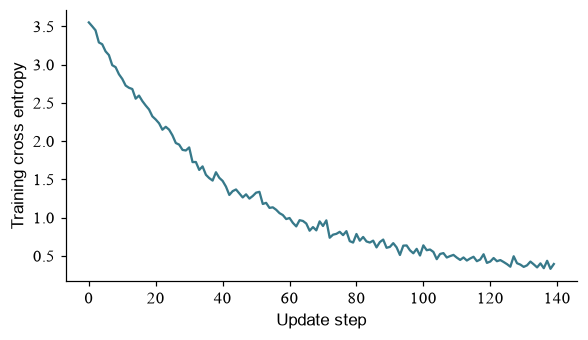

In [15]:
fig,ax = plt.subplots(figsize=(6,3.2))
ax.plot(history,color='#37798A')
ax.set(xlabel='Update step',ylabel='Training cross entropy')
show(fig)

In [16]:
@torch.no_grad()
def text_loss(data):
    model.eval()
    total,targets=0.,0
    for start in range(0,len(data)-1,context):
        length=min(context,len(data)-start-1)
        x=data[start:start+length][None,:]
        y=data[start+1:start+length+1]
        total+=F.cross_entropy(model(x).reshape(-1,len(alphabet)),y,reduction='sum').item()
        targets+=length
    return total/targets
print('validation CE:',text_loss(val_ids),'test CE:',text_loss(test_ids))

validation CE: 0.4196016479421545 test CE: 0.4209202499616714


## 4 给结果找一个容易解释的基线

Unigram 基线只数训练字符频率，不读取上下文。给每个字符加 1 个计数，概率为 $(n_c+1)/(N+V)$，测试损失是对应负对数概率的平均。

In [17]:
counts = torch.bincount(train_ids,minlength=len(alphabet)).float()+1
unigram = counts/counts.sum()
baseline_loss = -unigram[test_ids[1:]].log().mean().item()
print('unigram test CE:',baseline_loss,'decoder test CE:',text_loss(test_ids))

unigram test CE: 2.870845079421997 decoder test CE: 0.4209202499616714


### 练习 g04：从一个概率得到负对数损失

正确 token 概率为 0.25，计算单位置的交叉熵。

In [18]:
ex_g04_loss = None

In [19]:
# 填写上一格后，运行检查。
check('单位置loss',ex_g04_loss,np.log(4))

待填写：单位置loss


<details>
<summary>提示</summary>

用自然对数：-log(p)。

</details>

<details>
<summary>参考答案</summary>

```python
ex_g04_loss=-np.log(.25)
```

</details>

## 5 生成就是反复追加一个 token

训练时答案来自原文，生成时却要把自己的选择接回输入。给定 `the `，读取最后一个位置的词表分数，转成概率、抽取一个字符、接到末尾；重复这个动作，就从一次预测变成了一段文本。

模型每轮读取当前文本最后至多 T 个 token。温度 τ 是分数除以的正数：温度低时，高分字符占比更大；温度高时，抽到其他字符的机会增加。下一格只追加一次，后面再连续生成70个字符。

In [20]:
prefix = encode('the ')[None,:]
model.eval()
with torch.no_grad():
    last_logits=model(prefix)[:,-1,:]
    probabilities=torch.softmax(last_logits/.8,dim=-1)
    next_id=torch.multinomial(probabilities,num_samples=1)
    extended=torch.cat([prefix,next_id],dim=1)
print('追加一个字符：',repr(decode(extended[0])))

追加一个字符： 'the s'


In [21]:
torch.manual_seed(8)
generated=model.generate(prefix,steps=70,temperature=.8)
print(decode(generated[0]))

the moon rises quieietly.
the mooon moves slowly.
the sun sun glowly.
the 


### 练习 g05：把采样改为贪心选择

从 last_logits 选分数最高的 ID，形状保留为 `(1,1)` 以便追加。

In [22]:
ex_g05_id = None

In [23]:
# 填写上一格后，运行检查。
check('贪心选择',ex_g05_id,last_logits.argmax(dim=-1,keepdim=True))

待填写：贪心选择


<details>
<summary>提示</summary>

`argmax(dim=-1,keepdim=True)`。

</details>

<details>
<summary>参考答案</summary>

```python
ex_g05_id=last_logits.argmax(dim=-1,keepdim=True)
```

</details>

保存参数时同时保存构建配置，重新加载后核对同一个输入的 logits。训练状态与数据划分记录也应跟着实验保存。

In [24]:
artifact = ROOT/'.build'/'artifacts'
artifact.mkdir(parents=True,exist_ok=True)
torch.save(dict(config=config,state_dict=model.state_dict()),artifact/'tiny_gpt.pt')
saved=torch.load(artifact/'tiny_gpt.pt',map_location='cpu',weights_only=True)
restored=TinyGPT(**saved['config'])
restored.load_state_dict(saved['state_dict']); restored.eval()
check('保存后重建同一模型',restored(prefix),model(prefix))

通过：保存后重建同一模型


### 练习 g06：数一数更新的参数

使用 model.parameters()，计算所有可训练参数的标量总数。

In [25]:
ex_g06_count = None

In [26]:
# 填写上一格后，运行检查。
check('参数总数',ex_g06_count,sum(p.numel() for p in model.parameters()))

待填写：参数总数


<details>
<summary>提示</summary>

每个 p.numel() 是该张量的元素数，把这些数相加。

</details>

<details>
<summary>参考答案</summary>

```python
ex_g06_count=sum(p.numel() for p in model.parameters())
```

</details>

## 独立实验

固定句子划分，比较 width=12 与 width=24，各运行三个种子。记录参数量、训练/验证损失和更新次数。用验证结果选择配置后，统一查看测试结果。保留生成文本中的重复、断词和语法错误，逐类判断模型已经学到了哪些局部规律。

## 带着问题读原文

[minGPT 的字符模型项目](https://github.com/karpathy/minGPT/tree/master/projects/chargpt)

找出 Dataset 返回的 x、y 和这里错开一位的切片。沿一条 batch 追踪到 model.forward、交叉熵、backward、optimizer.step。